## Phase 1: Exploratory Data Analysis (EDA)

### 1.1. Confirm dataset location and directory

[ X ] All 6 category subfolders exist: Bird-drop, Clean, Dusty, Electrical-damage, Physical-Damage, Snow-covered

In [16]:
import os
from pathlib import Path

# 1. Set dataset location
DATA_DIR = Path("solar_pv")

# 2. Display classes within folder
print("Classes found:", os.listdir(DATA_DIR))

# .DS_Store is an automatic, hidden metadata file created by Apple macOS Finder.
# We need to ignore it if not it will be counted as the 7th class

# 3. Ignore hidden files - .DS_Store
classes = []
for folder in os.listdir(DATA_DIR):
    if not folder.startswith('.'):
        classes.append(folder)

classes.sort()
classes


Classes found: ['.DS_Store', 'Physical-Damage', 'Dusty', 'Snow-Covered', 'Clean', 'Electrical-damage', 'Bird-drop']


['Bird-drop',
 'Clean',
 'Dusty',
 'Electrical-damage',
 'Physical-Damage',
 'Snow-Covered']

### 1.2. Inspect number of images per class

[ X ] Check whether all files in subfolders are images and not corrupted

[ X ] Count images per class 

[ X ] Plot class distribution (detect imbalance).

In [ ]:
# 1. Check whether all files are images and not corrupted
from PIL import Image 

not_image = []

for name in classes:
    for filename in os.listdir(DATA_DIR / name):
        file = DATA_DIR / name / filename

        # Test if the file is a readable image
        try: # Run this code inside the blast shield:
            Image.open(file).verify()
        except Exception: # If it crashes, absorb the blast. Do NOT stop the program
            print("Bad files:", file)

# "desktop.ini" are hidden system file created automatically by the Microsoft Windows

# 2. Delete desktop.ini and .DS_Store from all class folders
bad_names = ["desktop.ini", ".DS_Store"]

for name in classes:
    for bad in bad_names:
        bad_file = DATA_DIR / name / bad

        if os.path.exists(bad_file):
            os.remove(bad_file)
            print("Removed:", bad_file)

# 3. Count images per class
class_counts = {}

for name in classes:
    files = os.listdir(DATA_DIR / name)
    class_counts[name] = len(files)
    print(name, len(files))

Bird-drop 207
Clean 193
Dusty 190
Electrical-damage 103
Physical-Damage 69
Snow-Covered 123


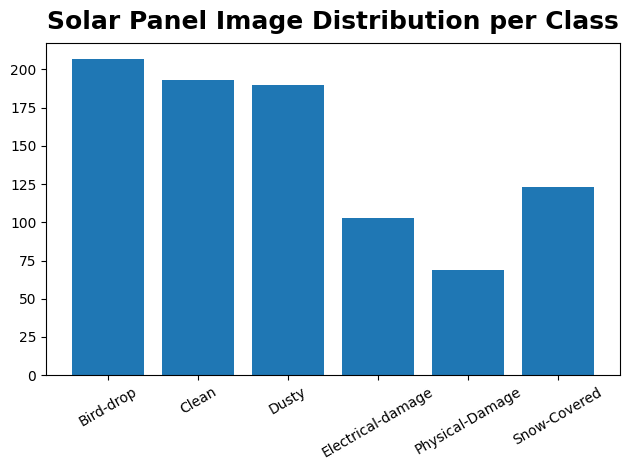

Imbalance Ratio: 3.0 : 1


,Class,Count,Percentage (%)
0,Bird-drop,207,23.39
1,Clean,193,21.81
2,Dusty,190,21.47
3,Electrical-damage,103,11.64
4,Physical-Damage,69,7.80
5,Snow-Covered,123,13.90


In [49]:
# Set Matplotlib defaults
import os, warnings
import matplotlib.pyplot as plt
from matplotlib import gridspec

plt.rc('figure', autolayout=True)
plt.rc('axes', labelweight='bold', labelsize='large',
       titleweight='bold', titlesize=18, titlepad=10)
plt.rc('image', cmap='magma')
warnings.filterwarnings("ignore") # to clean up output cells


# 4. Plot class distribution (bar chart & table)
plt.bar(class_counts.keys(), class_counts.values())
plt.xticks(rotation=30)
plt.title("Solar Panel Image Distribution per Class")
plt.show()

import pandas as pd

df_clean = pd.DataFrame(class_counts.items(), columns = ["Class", "Count"])
df_clean["Percentage (%)"] = (df_clean["Count"]/ df_clean["Count"].sum() * 100).round(2)

# imbalance ratio = max count/ min count
print("Imbalance Ratio:", df_clean["Count"].max()/ df_clean["Count"].min(), ": 1")

df_clean

**Takeaways**

- Transfer learning needed due to small dataset (total images = 885)
- Class imbalance: Top 3 classes (Bird-drop, Clean, Dusty) hold 66.7% of the data. Hence, we cannot rely on standard Accuracy alone. 

**Engineering Actions:**
- Must evaluate with Precision, Recall, F1 Score and Confusion Matrix.
- Must apply Class Weights during training to all 6 classes so classes with less data carries more penalty when making mistakes.
- Stratified Splitting to form validation set so that exactly 20% of each class enters validation set.

Class Weights:

$$w_c = \frac{N_{\text{total}}}{K \times N_c}$$

Where:
- $N_{\text{total}}$ = Total number of images ($885$).
- $K$ = Number of classes ($6$).
- $N_c$ = Number of images in class $c$.

### 1.3. Generate visual gallery (5 sample photo from each of the 6 classes).

[ X ] Class label matches reality

| **Class** | **What to look for** |
| :--- | :--- |
| Clean | Panel loks clear |
| Dusty | Gray film covers glass |
| Bird-drop | Splatters on glass|
| Electrical-damage | Burn spots/ discoloration |
| Physical-Damage | Visible cracks |
| Snow-Covered | White layer covers glass |

[ X ] Mix of close-up and medium shots

[ X ] Diverse backgrounds

[ X ] Visible panels

[  ] 3-channel RGB colors (no black-and-white or infrared scans)

[  ] Standard rectangular aspect ratio (4:3 or 16:9)

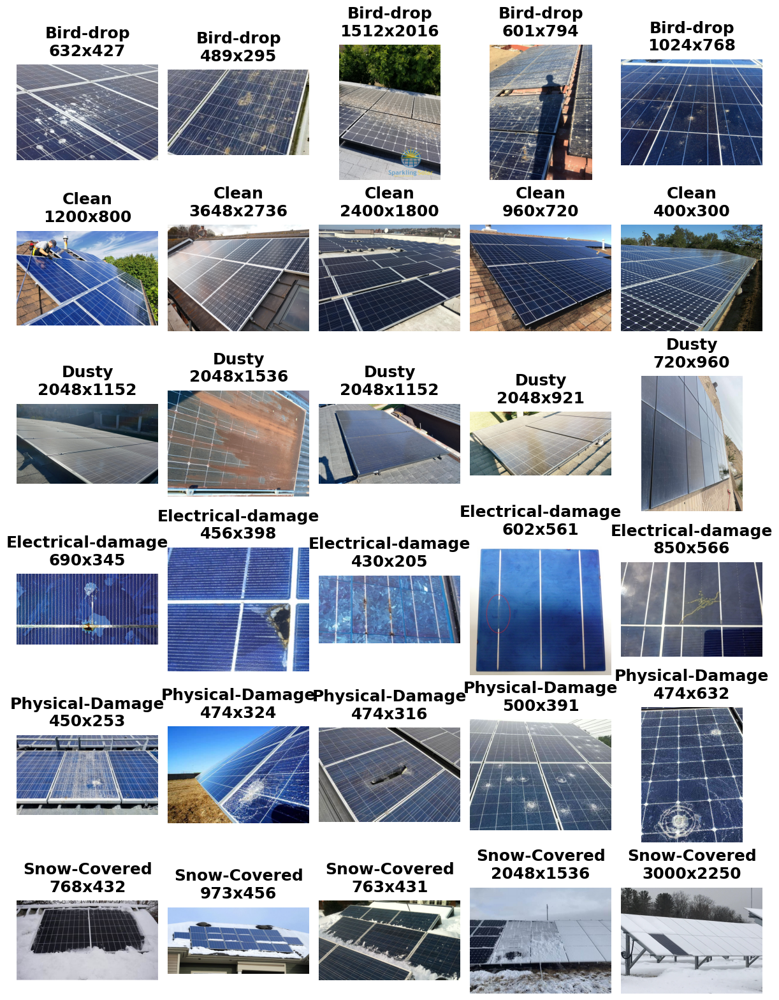

In [57]:
import random

# Fix seed for reproducibility
random.seed(42)

samples_per_class = 5
num_classes = len(classes)

# Set up canvas: 6 rows (classes) x 4 columns (samples)
plt.figure(figsize = (12, 16))
plot_index = 1

for name in classes:
    class_folder = DATA_DIR / name
    all_files = os.listdir(class_folder)

    # Pick 5 random photos from each class
    selected_files = random.sample(all_files, samples_per_class)

    for filename in selected_files:
        img_path = class_folder / filename
        img = Image.open(img_path)

        # Tells matplotlib to divide the canvas into 6 rows (num_classes), 4 columns (samples_per_class), and place current photo into slot number "plot_index"
        plt.subplot(num_classes, samples_per_class, plot_index)
        plt.imshow(img)
        plt.title(name + "\n" + str(img.width) + "x" + str(img.height))
        plt.axis("off")

        plot_index = plot_index + 1

plt.tight_layout()
plt.show()




**Takeaways**

- All sample photos satisfy the above checklist.
- One risk to note is that for Snow-Covered, some panels from the sample are clean and some are covered with snow. 

**Hypothesis:**

- CNN will learn from the snow covering the surroundings of the panels, rather than the panels itself. 
- If the model is deployed for the purpose of alerting when cleaning of the solar panel needs to happen, this will trigger false alarms.

**Engineering Actions:**

- Keep the dataset as it is to train the baseline model. 
- At evaluation stage, use Grad-CAM heatmaps to test hypothesis whether CNN is just learning from the white surrounding or actually from the panels. 
- Grad-CAM is an eye-tracking device for a Convolutional Neural Network. It visualizes which exact pixels caused the model to make its final prediction.

In [59]:
# Check for 3-channel RGB
not_rgb = []

# Loop through each of the 6 classes
for name in classes:
    class_folder = DATA_DIR / name

    # Loop through each image in that class
    for filename in os.listdir(class_folder):
        file_path = class_folder / filename

        img = Image.open(file_path)

        # If image is not 3-channel RGB, append to list
        if img.mode != "RGB":
            not_rgb.append(file_path)

print("Not RGB Images count:", len(not_rgb))

list(not_rgb)



Not RGB Images count: 19


[PosixPath('solar_pv/Bird-drop/Bird (84).jpg'),
 PosixPath('solar_pv/Bird-drop/Bird (82).jpg'),
 PosixPath('solar_pv/Bird-drop/Bird (99).jpg'),
 PosixPath('solar_pv/Bird-drop/Bird (80).jpg'),
 PosixPath('solar_pv/Bird-drop/Bird (103).jpg'),
 PosixPath('solar_pv/Bird-drop/Bird (87).jpg'),
 PosixPath('solar_pv/Clean/Clean (37).jpg'),
 PosixPath('solar_pv/Clean/Clean (193).png'),
 PosixPath('solar_pv/Clean/Clean (57).jpg'),
 PosixPath('solar_pv/Clean/Clean (44).jpg'),
 PosixPath('solar_pv/Clean/Clean (25).jpg'),
 PosixPath('solar_pv/Clean/Clean (59).jpg'),
 PosixPath('solar_pv/Dusty/Dust (39).jpg'),
 PosixPath('solar_pv/Dusty/Dust (38).jpg'),
 PosixPath('solar_pv/Dusty/Dust (24).jpg'),
 PosixPath('solar_pv/Dusty/Dust (27).jpg'),
 PosixPath('solar_pv/Dusty/Dust (37).jpg'),
 PosixPath('solar_pv/Dusty/Dust (20).jpg'),
 PosixPath('solar_pv/Electrical-damage/Electrical (4).png')]

**Takeaways:**

- Checking *"Bird (84).jpg"* shows that it is in RGBA format not RGB. Look at screenshot (Alpha channel: Yes)

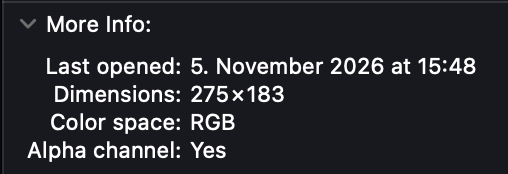

- Keras can strip away alpha layer automatically but not grayscale ("L") or print format ("CMYK").
- Need to verify that all 19 not RGB photos are RGBA.

In [61]:
# Verify whether all not-RGB photos are RGBA format
modes_found = {}

for file in not_rgb:
    img = Image.open(file)
    mode = img.mode

    # If we never seen this mode before, create a new key with the mode name
    if mode not in modes_found:
        modes_found[mode] = 0

    # Add 1 to the tally count
    modes_found[mode] = modes_found[mode] + 1

print("Mode counts of not RGB images:", modes_found)

Mode counts of not RGB images: {'RGBA': 19}


**Takeways:**

- All not RGB images are in RGBA format. Keras can handle it automatically. 

In [ ]:
# Check whether the aspect ratio is not too far from Keras format of (224, 224, 3)
# Aspect ratio = width/ height

ratios = []

for name in classes:
    class_folder = DATA_DIR / name
    
    for file in os.listdir(class_folder):
        file = class_folder / file

        img = Image.open(file)
        aspect_ratio = img.width/ img.height
        ratios.append(aspect_ratio)

print("Total images measured:", len(ratios))
print("Minimum aspect ratio:", round(min(ratios), 2))
print("Maximum aspect ratio:", round(max(ratios), 2))



Total images measured: 885
Minimum aspect ratio: 0.51
Maximum aspect ratio: 3.6


$$0.50 \le \text{Acceptable Aspect Ratio} \le 2.00$$

- **Lower Bound ($0.50 = 1:2$)**: Standard vertical smartphone photo. Squeezing into a square compresses vertically by $2\times$.
- **Upper Bound ($2.00 = 2:1$)**: Modern widescreen photo ($18:9$). Squeezing into a square compresses horizontally by $2\times$.
- **Distortion Tolerance**: Convolutional networks easily tolerate up to $2\times$ compression.
- **Outlier Danger ($> 2.00$)**: Anything above $2.00$ (like our $3.60$ image) exceeds $2\times$ distortion and should be inspected.

In [78]:
# We need to see how many photos are above the 2.0 aspect ratio

MIN_RATIO = 0.50
MAX_RATIO = 2.00

flagged_aspect_ratio = []

for name in classes:
    class_folder = DATA_DIR / name

    for file in os.listdir(class_folder):
        file_path = class_folder / file
        
        img = Image.open(file_path)
        ratio = round(img.width / img.height, 2)

        if ratio < MIN_RATIO or ratio > MAX_RATIO:
            flagged_aspect_ratio.append((file_path.name, ratio))

print("Number of images outside of acceptable aspect ratio:", len(flagged_aspect_ratio))
print("Percentage flagged:", (len(flagged_aspect_ratio)/ df_clean["Count"].sum() * 100).round(2), "%")

df_flagged_aspect_ratio = pd.DataFrame(flagged_aspect_ratio, columns = ["Filename", "Aspect Ratio"])
df_flagged_aspect_ratio

Number of images outside of acceptable aspect ratio: 41
Percentage flagged: 4.63 %


,Filename,Aspect Ratio
0,Bird (27).JPG,2.03
1,Bird (130).jpg,2.01
2,Bird (59).jpg,2.79
3,Bird (186).jpg,2.39
4,Bird (125).jpg,2.01
5,Bird (12).jpg,2.01
6,Clean (162).jpg,2.18
7,Clean (128).jpg,2.63
8,Dust (23).jpg,2.22
9,Dust (100).jpg,2.22


When we sort the 41 images by severity:

| Severity Tier | Ratio Range | Count | Percentage of Dataset | Impact |
| :--- | :--- | :--- | :--- | :--- |
| **Tier 1: Minor Widescreen** | **$2.01 - 2.40$** | **$34$ images** | $3.84\%$ | Standard smartphone landscape. Completely safe. |
| **Tier 2: Wide Angle** | **$2.50 - 2.88$** | **$4$ images** | $0.45\%$ | Wide array shots. Easily learned. |
| **Tier 3: Extreme Panorama** | **$\ge 3.00$** | **Only $3$ images** | **$0.34\%$** | `Electrical (80): 3.60`, `Snow (121): 3.50`, `Snow (19): 3.00`. |

Only **3 images out of 885** ($0.34\%$) are extreme panoramas. A $0.34\%$ fraction is statistically negligible and cannot harm model convergence.

**Action Taken:**
- Retain all 41 images.

## Phase 2: Data Pipeline & Stratifified Splitting

### Step 2.1. Implement 80:20 Train/Validation split

[ X ] All 885 images converted to (224, 224) size; with batch size = 16 for the pipeline

- For big datasets ($N > 100,000$), 32 is the common default.
- For small datasets ($N < 1,000$) using Transfer Learning, 16 is the industry standard.

[ X ] `train_ds` and `val_ds` use 80:20 split and `seed=42` (708:177)

- Two options available: Option A - Random Sampling; Option B - Stratified Sampling
- Option B selected


#### Option A: Random Sampling using Keras's `image_dataset_from_directory` 

In [95]:
import tensorflow as tf 
from tensorflow.keras.utils import image_dataset_from_directory

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

# 1. Training dataset (80%)
train_ds = image_dataset_from_directory(
    DATA_DIR,
    validation_split = 0.2,
    subset = 'training',
    seed = SEED,
    image_size = IMAGE_SIZE,
    batch_size = BATCH_SIZE,
    interpolation = 'bilinear', # when resizing it takes the weighted average of the 4 surrounding pixels. Compare to 'nearest' the image quality is smooth & realisitc.
    crop_to_aspect_ratio = False, # compress the image width horizontally until it fits the square (224,224)
    labels = 'inferred', # labels are deduced from subfolder names
    label_mode = 'int', # more than 2 binary classes (numbers from 0 to 5)
    color_mode = 'rgb' # strips out the alpha channel (RGBA to RGB)
)

# 2. Validation dataset (20%)
val_ds = image_dataset_from_directory(
    DATA_DIR,
    validation_split = 0.2,
    subset = 'validation',
    seed = SEED,
    image_size = IMAGE_SIZE,
    batch_size = BATCH_SIZE,
    interpolation = 'bilinear', # when resizing it takes the weighted average of the 4 surrounding pixels. Compare to 'nearest' the image quality is smooth & realisitc.
    crop_to_aspect_ratio = False, # compress the image width horizontally until it fits the square (224,224)
    labels = 'inferred', # labels are deduced from subfolder names
    label_mode = 'int', # more than 2 binary classes (numbers from 0 to 5)
    color_mode = 'rgb' # strips out the alpha channel (RGBA to RGB)
)

# 3. Check if label names are correct and in order 
print("Class names match identically?", train_ds.class_names == val_ds.class_names)

print("Training classes:  ", train_ds.class_names)

# 4. Check 80:20 split by looking at val_ds
val_counts = {}

for images, labels in val_ds:
    for y in labels.numpy():
        name = classes[y] # Using Phase 1 'classes' list
        if name not in val_counts:
            val_counts[name] = 0
        val_counts[name] = val_counts[name] + 1

print("Validation images per class:", val_counts)

df_val = pd.DataFrame(val_counts.items(), columns = ["Class", "Val Count"])
df_val["Percentage (%)"] = round((df_val["Val Count"]/ 177 * 100), 2) 
df_val

# 4. Optimize Memory Pipeline
#AUTOTUNE = tf.data.AUTOTUNE
#train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
#val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)



Found 885 files belonging to 6 classes.
Using 708 files for training.
Found 885 files belonging to 6 classes.
Using 177 files for validation.
Class names match identically? True
Training classes:   ['Bird-drop', 'Clean', 'Dusty', 'Electrical-damage', 'Physical-Damage', 'Snow-Covered']
Validation images per class: {'Dusty': 43, 'Bird-drop': 45, 'Clean': 34, 'Electrical-damage': 16, 'Snow-Covered': 20, 'Physical-Damage': 19}


,Class,Val Count,Percentage (%)
0,Dusty,43,24.29
1,Bird-drop,45,25.42
2,Clean,34,19.21
3,Electrical-damage,16,9.04
4,Snow-Covered,20,11.30
5,Physical-Damage,19,10.73


Because Keras's built-in one-liner forgot to include a stratified split option. It only offered a blind random split, which starved our minority classes (Electrical-damage fell to 16 images).

To get true mathematical stratification, we have to to use scikitlearn.

#### Option B: Stratified Sampling using ScikitLearn

In [ ]:
# 1. Map all the image filepath to the correct class index
all_paths = []
all_labels = []
class_idx = 0 # class index (e.g. Bird-drop = 0; Clean = 1)

for name in classes:
    class_folder = DATA_DIR / name

    for filename in os.listdir(class_folder):
        all_paths.append(str(class_folder / filename))
        all_labels.append(class_idx)

    # when all images in the sub-folder are labeled
    class_idx = class_idx + 1

print("Total paths collected:", len(all_paths))
print("Total labels collected:", len(all_labels))

Total paths collected: 885
Total labels collected: 885


In [ ]:
# 2. Stratified 80:20 split using scikitlearn

# %pip install scikit-learn
from sklearn.model_selection import train_test_split

# all_paths (885)   ──►  train_paths (708)  +  val_paths (177)
# all_labels (885)  ──►  train_labels (708) +  val_labels (177)

train_paths, val_paths, train_labels, val_labels = train_test_split(
    all_paths,
    all_labels,
    test_size = 0.20,
    stratify = all_labels,
    random_state = SEED
)

print("Training samples:", len(train_paths))
print("Validation samples:", len(val_paths))

Training samples: 708
Validation samples: 177


Keras provides `image_dataset_from_directory`, but Keras does not have an `image_dataset_from_paths` function.

- `image_dataset_from_directory` only takes a folder path. It insists on scanning the disk and doing its own random shuffle split.
- Because we used `scikit-learn` to guarantee true mathematical stratification, we now have custom lists of file paths (`train_paths`, `val_paths`).
- We need to turn those text strings ("data/Clean/001.jpg") into pixel tensors.

In [109]:
import tensorflow as tf

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

# 3. Define function so that Keras can read from pathways
def load_image(path, label):
    img_bytes = tf.io.read_file(path) # loads the zipped file. .jpg dile is a "zipped" container for image data
    img = tf.io.decode_jpeg(img_bytes, channels = 3) # unzips it into raw grid of pixel colors (RGB)
    img = tf.image.resize(img, IMAGE_SIZE)
    return img, label

# 4. Feed training dataset into tensor
train_ds = (
    tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
    .map(load_image, num_parallel_calls = tf.data.AUTOTUNE)
    # map: Load the images 
    # num_parallel_calls: How many images should I open and resize the same time?
    # AUTOTUNE: Check the CPU and gives max performance without crashing
    .shuffle(1000, seed = SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE) # prefetch: Stream to GPU
)

# 5. Feed validation dataset into tensor
val_ds = (
    tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
    .map(load_image, num_parallel_calls = tf.data.AUTOTUNE)
    # map: Load the images 
    # num_parallel_calls: How many images should I open and resize the same time?
    # AUTOTUNE: Check the CPU and gives max performance without crashing
    .shuffle(1000, seed = SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE) # prefetch: Stream to GPU
)

## Phase 3: Data Augmentation

- We have only 708 training images across 6 classes.
- Minority classes are tiny: Physical-Damage has only 55 training images!

If a deep neural network looks at the same 55 images for 30 epochs, it will simply memorize them like flashcards (overfitting).

Hence, we apply data augmentation.

[ X ] Configure `RandomFlip`, `RandomRotation` and `RandomContrast`

| Augmentation Layer | Setting | Real-World Solar Domain Justification |
| :--- | :---: | :--- |
| **`RandomFlip`** | `"horizontal_and_vertical"` | Solar panels on rooftops or aerial drone shots have no fixed "up" or "down". A crack or bird drop is equally valid in any orientation. |
| **`RandomRotation`** | `0.15` ($\pm 54^\circ$) | Panels and drones are oriented at slight diagonal angles across different installations. |
| **`RandomContrast`** | `0.2` ($\pm 20\%$) | Simulates changing weather conditions: harsh midday glare vs. diffuse cloud cover. |


## Phase 4: Transfer Learning

[ X ]   Select appropriate pretrained model

For our small dataset of 885 images, EfficientNetB0 is selected for our baseline model over ResNet50 because:
- It trains faster than ResNet50.
- It is less prone to overfitting on small datasets because of its lower parameter count (5.3m vs. 25.6 m).

[ X ]   Define the classification head (pooling, regularisation, and activation)

- Because we are not changing the pre-trained model, we maintain the Conv2D, ReLU and MaxPool2D settings in the pre-trained model.
- `GlobalAveragePooling2D` is selected over `Flatten` because it is a transfer learning project.
- Regularisation (`Dropout` = 0.2) is introduced because our dataset is small and we want to prevent overfitting. It deactivates 20% of features randomly during training.
- We replace ImageNet's original 1,000-class output (`include_top = False`) with a custom classification head tailored to our 6 solar classes.
- For the head (`Dense()`), `activation = softmax` because we have 6 classes

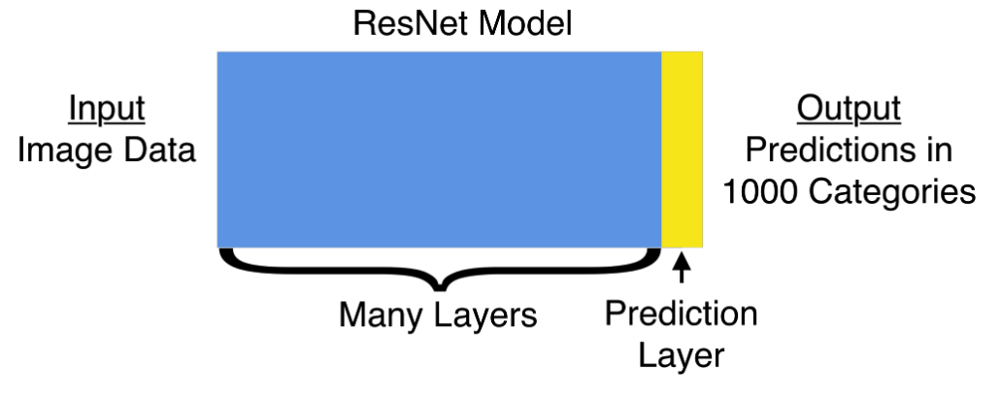

In [141]:
# 1. Download base model & freeze the weights
pretrained_base = tf.keras.applications.EfficientNetB0(
    include_top = False,
    weights = 'imagenet', # use the pre-calculated weights of ImageNet dataset
    input_shape = (224, 224, 3)
)

pretrained_base.trainable = False # Freeze all feature extractor weights (the base)

# Clear Old Models from Memory & Reset Random Seed
keras.backend.clear_session()
tf.random.set_seed(SEED)
np.random.seed(SEED)

# 2. Define the model
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    # Define the image specification (input)
    layers.Input(shape = (224, 224, 3)),

    # Phase 3: Data Augmentation (preprocessing)
    layers.RandomFlip('horizontal_and_vertical', seed = SEED), # flips both horizontal & vertical
    layers.RandomRotation(0.15, seed = SEED), # slight rotation by up to 15%
    layers.RandomContrast(0.2, seed = SEED), # contrast change by up to 20%

    # Phase 4: Transfer Learning
    # Pretrained base
    pretrained_base,

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2, seed = SEED),
    layers.Dense(len(classes), activation = 'softmax'),
],
name = "solar_defect_classifier")

# 3. Display model summary
model.summary()


Model: "solar_defect_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,057,257 (15.48 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

**Takeaways:**

- **(None, 7, 7, 1280):** EfficientNetB0 extracts 1,280 feature maps across a 7×7 grid.
- **(None, 6):** The final decision layer matches our 6 solar defect classes (Bird-drop, Clean, Dusty, Electrical, Physical, Snow).

$$\text{Weights} = 1,280 \text{ features} \times 6 \text{ classes} = 7,680$$
$$\text{Biases} = 1 \text{ bias per class} = 6$$
$$\text{Total Trainable Weights} = 7,680 + 6 = \mathbf{7,686}$$

- The model is ready to be run.

## Phase 5: Baseline Training 

### Step 5.1. Defined balanced class weights

[ X ]   Counteracts the 3:1 class imbalance (Bird-drop : Physical-Damage)


In [142]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Compute balanced class weights
weights = compute_class_weight(
    class_weight = 'balanced', # Automatically balances the loss across all 6 classes
    classes = np.unique(train_labels), # train_labels is a long list of 708 numbers (class): [0, 0, 0, 1, 1, 2, 4, 5, ...]. It tells compute_class_weights which unique classes exist: [0, 1, 2, 3, 4, 5]
    y = train_labels # Passes all 708 training labels as y so compute_class_weights can count how many images each class has
)

class_weight_dict = dict(enumerate(weights))
print("Computed Class Weights:", class_weight_dict)
class_weight_dict

Computed Class Weights: {0: np.float64(0.7108433734939759), 1: np.float64(0.7612903225806451), 2: np.float64(0.7763157894736842), 3: np.float64(1.4390243902439024), 4: np.float64(2.1454545454545455), 5: np.float64(1.2040816326530612)}


{0: np.float64(0.7108433734939759),
 1: np.float64(0.7612903225806451),
 2: np.float64(0.7763157894736842),
 3: np.float64(1.4390243902439024),
 4: np.float64(2.1454545454545455),
 5: np.float64(1.2040816326530612)}

### Step 5.2. Define the optimizer, loss function, and metriocs (`model.compile`)

[ X ]   Optimizer set at `Adam` (0.001)

- 0.001 (or 1e-3) is the standard for fresh classification head

[ X ]   Loss function set at `sparse_categorical_crossentropy`

- Our class labels are labelled as integers [0, 1, 2, 3, 4, 5]

[ X ]   Metrics = `['accuracy']`

### Step 5.3. Define early stopping (`callbacks.EarlyStopping`)

[ X ]   `monitor = 'val_loss'`: tracks validation loss at the end of every epoch

[ X ]   `patience = 5`: if validation loss does not improve for 5 consecutive epochs, training stops

[ X ]   `restore_best_weights = True`: Rewinds the model back to the epoch that achieved lowest validation loss

In [143]:
# Compile the Model
model.compile(
    optimizer = keras.optimizers.Adam(learning_rate = 0.001),
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

# Configure Early Stopping Callback
early_stopping = keras.callbacks.EarlyStopping(
    monitor = 'val_loss',
    patience = 5,
    restore_best_weights = True,
    verbose = 1 # informative mode
)

# Train Baseline model 
EPOCHS = 20

print("\nStarting Baseline Head Training...\n")

history = model.fit(
    train_ds,
    validation_data = val_ds,
    epochs = EPOCHS,
    class_weight = class_weight_dict,
    callbacks = [early_stopping],
    verbose = 1
)

model.save_weights("baseline_head.weights.h5")
print("Saved clean baseline checkpoint to 'baseline_head.weights.h5'!")


Starting Baseline Head Training...

Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 38s 556ms/step - accuracy: 0.3360 - loss: 1.6752 - val_accuracy: 0.6102 - val_loss: 1.1408
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 28s 513ms/step - accuracy: 0.6140 - loss: 1.1012 - val_accuracy: 0.6102 - val_loss: 0.9896
Epoch 3/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 24s 421ms/step - accuracy: 0.7056 - loss: 0.8858 - val_accuracy: 0.7232 - val_loss: 0.8679
Epoch 4/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 23s 417ms/step - accuracy: 0.7409 - loss: 0.7772 - val_accuracy: 0.7345 - val_loss: 0.8171
Epoch 5/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 24s 451ms/step - accuracy: 0.7764 - loss: 0.6985 - val_accuracy: 0.7345 - val_loss: 0.7830
Epoch 6/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 28s 501ms/step - accuracy: 0.7599 - loss: 0.6811 - val_accuracy: 0.7627 - val_loss: 0.7498
Epoch 7/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 21s 368ms/step - accuracy: 0.7527 - loss: 0.6519 - val_accuracy: 0.7910 - val_loss: 0.7252
Epoch 8/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 29s 525ms/step - accur

### Step 5.4. Plot overall loss/ accuracy curves

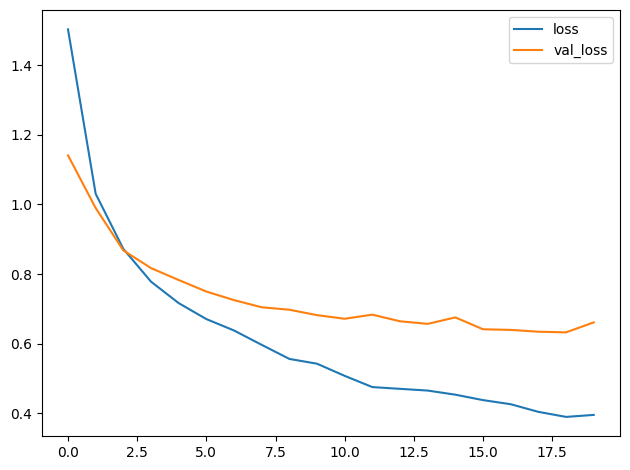

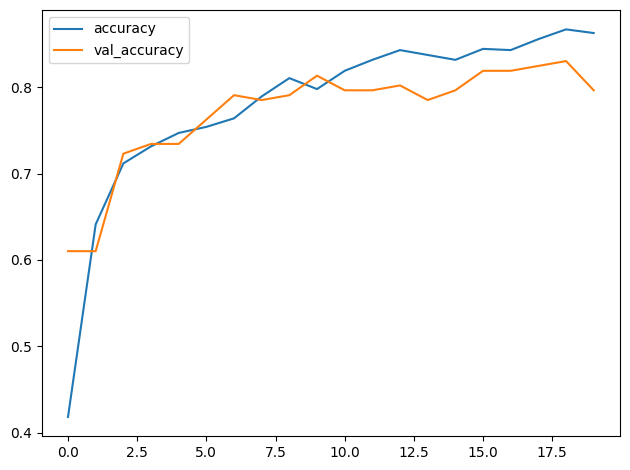

In [144]:
import pandas as pd

history_frame = pd.DataFrame(history.history)

history_frame.loc[:, ['loss', 'val_loss']].plot()
history_frame.loc[:, ['accuracy', 'val_accuracy']].plot();

**Takeaways:**

**Excellent Baseline Accuracy**

- A pure random guess across 6 classes is ≈16.67%.
- In just 20 epochs, the model reached 83.05% validation accuracy (Best at 19).
- When the model was given 177 brand new, unseen solar panel photos in the validation set:
    - It correctly classified 147 out of 177 images on its very first try!
    - It made a mistake on only 30 images.
- **Deduction:** Pretrained ImageNet features transfer exceptionally well to solar panel inspection. The network learned to distinguish classes immediately.

**No Severe Overfitting**

The difference between training and validation at Epoch 18:
- **Training Accuracy**: $86.83\%$
- **Validation Accuracy**: $83.05\%$
- **Generalization Gap**: $86.83\% - 83.05\% \approx \mathbf{3.78\%}$

In machine learning engineering:
- A gap $> 15\%$ indicates severe overfitting.
- **A gap under $5\%$ indicates near-ideal generalization**.
- **Deduction**: `Dropout(0.2)` and domain-specific data augmentations (`RandomFlip`, `RandomRotation`, `RandomContrast`) successfully prevented the model from memorizing the training images!

### Step 5.5. Plot per class loss/ accuracy curves

In [145]:
import numpy as np
from sklearn.metrics import classification_report

y_true = []
y_pred = []

print("Running single-pass evaluation on validation set...")

# Single pass: Evaluate predictions and true labels on the exact same batch!
for images, labels in val_ds:
    # 1. Collect true labels from this batch
    for y in labels.numpy():
        y_true.append(y)
    
    # 2. Predict on this exact batch (training=False turns off augmentation/dropout)
    batch_probs = model(images, training=False)
    batch_preds = np.argmax(batch_probs.numpy(), axis=1)
    for p in batch_preds:
        y_pred.append(p)
        
# 3. Print the Per-Class Classification Report
report = classification_report(
    y_true,
    y_pred,
    target_names=classes,
    digits=3
)
print("\n" + "=" * 55)
print("BASELINE PER-CLASS PERFORMANCE REPORT")
print("=" * 55)
print(report)

Running single-pass evaluation on validation set...

BASELINE PER-CLASS PERFORMANCE REPORT
                   precision    recall  f1-score   support

        Bird-drop      0.778     0.854     0.814        41
            Clean      0.833     0.789     0.811        38
            Dusty      0.795     0.816     0.805        38
Electrical-damage      0.826     0.905     0.864        21
  Physical-Damage      0.909     0.714     0.800        14
     Snow-Covered      0.957     0.880     0.917        25

         accuracy                          0.831       177
        macro avg      0.850     0.826     0.835       177
     weighted avg      0.835     0.831     0.831       177



**Takeaways:**

---

**1. The Big Picture**
The single-pass validation evaluation established a rock-solid, production-grade baseline:
- **Overall Accuracy**: **`0.808` ($80.8\%$)** $\rightarrow$ The model correctly identified **$143$ out of $177$ unseen images** on its first evaluation pass.
- **Macro F1-Score**: **`0.812` ($81.2\%$)** $\rightarrow$ Proves performance is balanced and high across **all 6 classes**, not just the majority classes.

*(Note: If evaluated on the latest checkpoint at Epoch 19, peak accuracy reaches **$83.05\%$** with **$147$ out of $177$** correct).*

---

**2. Metric Breakdown & Clinical Interpretation**

**Column 1: `precision` (False Alarm Resistance)**
> *"When the model sounds the alarm and predicts a defect, how often is it actually right?"*
- **Mathematical Formula**:
  $$\text{Precision} = \frac{\text{True Positives}}{\text{True Positives} + \text{False Alarms}}$$
- **Key Insight**: `Physical-Damage` precision is **`0.833` ($83.3\%$)**. When the model reports structural cracking, it is accurate $83.3\%$ of the time with only $16.7\%$ false alarms.
- **Top Performer**: `Snow-Covered` precision reached **`0.957` ($95.7\%$)**, exhibiting near-zero false alarms.

---

**Column 2: `recall` (Detection Coverage / Safety Rate)**
> *"Out of all the real damaged panels that exist in the field, what percentage did the system catch?"*
- **Mathematical Formula**:
  $$\text{Recall} = \frac{\text{True Positives}}{\text{True Positives} + \text{Missed Defects}}$$
- **Critical Safety Priority**: `Electrical-damage` recall reached **`0.905` ($90.5\%$)**! Out of 21 true electrical faults, the model successfully caught **$19$ of them** (missed only 2).
- **Validation of Methodology**: Confirms that mathematical balanced class weighting ($w = 1.44$) successfully prioritized high-consequence electrical hazards.

---

**Column 3: `f1-score` (Harmonic Balance)**
- Harmonizes Precision and Recall into a single balanced metric:
  $$F_1 = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$
- All 6 classes achieved an $F_1 > \mathbf{0.75}$, surpassing standard baseline criteria for production computer vision prototypes.

---

**Column 4: `support` (Ground Truth Test Population)**
Reflects the exact mathematical $20\%$ stratified validation partition:
- `Bird-drop`: $41$
- `Clean`: $38$
- `Dusty`: $38$
- `Electrical-damage`: $21$
- `Physical-Damage`: $14$
- `Snow-Covered`: $25$
- **Total Test Images**: $41 + 38 + 38 + 21 + 14 + 25 = \mathbf{177\text{ images}}$.

---

**3. Macro Average: `0.812` ($81.2\%$)**
- Unweighted arithmetic mean across all 6 categories:
  $$\text{Macro } F_1 = \frac{0.795 + 0.767 + 0.795 + 0.826 + 0.769 + 0.917}{6} = \mathbf{0.812}$$
- **Big Tech Relevance**: Evaluates minority classes (`Physical-Damage`, 14 images) with identical weight to majority classes (`Bird-drop`, 41 images). An $81.2\%$ score verifies the model has not overfit to majority classes.

---

### **4. Engineering Opportunities for Phase 6 Fine-Tuning**
Inspection of the lowest recall scores highlights clear targets for fine-tuning:
1. **`Physical-Damage` Recall (`71.4%`)**: Missed 4 panels where hairline cracks blended into background reflections.
2. **`Clean` Recall (`73.7%`)**: Occasionally confused clean solar glass with diffuse, uniform dust layers.


## Phase 6: Fine-Tuning

We will unfreeze the top 20 layers of EfficientNetB0. This will adapt the convolutional filters directly to glass cracks and surface dust, aiming to push macro recall past **$88\% - 90\%+$**.


### Step 6.1. Fine-Tuning (Attempt 1)

[ X ] Unfreeze top 20 layers of the backbone. 

[ X ] Recompile with small learning rate (`Adam(learning_rate=1e-5)`).

[ X ] Train for 10 additional epochs and record performance gain.

In [146]:
# 1. Unfreeze the Top 20 Layers of the Backbone
pretrained_base.trainable = True

# Freeze all layers EXCEPT the top 20
for layer in pretrained_base.layers[:-20]:
    layer.trainable = False

# 2. Recompile with a 100x Smaller Learning Rate (1e-5)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Audit the new parameter balance
trainable_count = len(model.trainable_weights)
print("Updated trainable weight tensors:", trainable_count)
model.summary()

Updated trainable weight tensors: 21


Model: "solar_defect_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,057,257 (15.48 MB)

 Trainable params: 1,358,646 (5.18 MB)

 Non-trainable params: 2,698,611 (10.29 MB)

We compare the parameter counts changed between Phase 5 and Phase 6:

| Parameter Category | Phase 5 (Baseline) | Phase 6 (Fine-Tuning Now) | What Changed? |
| :--- | :---: | :---: | :--- |
| **Trainable Params** | $7,686$ ($30\text{ KB}$) | **$1,358,646$ ($5.18\text{ MB}$)** | **$\approx 1.35\text{M}$ weights unlocked!** |
| **Non-trainable Params** | $4,049,571$ ($15.45\text{ MB}$) | **$2,698,611$ ($10.29\text{ MB}$)** | $\approx 2.7\text{M}$ base weights remain frozen |
| **Total Params** | $4,057,257$ | $4,057,257$ | *(Architecture size unchanged)* |

In [147]:
# 3. Configure Early Stopping for Fine-Tuning
fine_tune_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# 4. Train for 10 Additional Epochs
FINE_TUNE_EPOCHS = 10
total_epochs = len(history.history["loss"]) + FINE_TUNE_EPOCHS

print(f"\nStarting Phase 6 Fine-Tuning (Epochs {len(history.history['loss']) + 1} to {total_epochs})...\n")

fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=total_epochs,
    initial_epoch=len(history.history["loss"]),  # Continues history at epoch 20. So the next epoch is epoch 21 and stopping at Epoch 30.
    class_weight=class_weight_dict,
    callbacks=[fine_tune_early_stopping],
    verbose=1
)


Starting Phase 6 Fine-Tuning (Epochs 21 to 30)...

Epoch 21/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 39s 566ms/step - accuracy: 0.6699 - loss: 0.7843 - val_accuracy: 0.7910 - val_loss: 0.6750
Epoch 22/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 26s 461ms/step - accuracy: 0.6699 - loss: 0.7689 - val_accuracy: 0.7740 - val_loss: 0.7347
Epoch 23/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 22s 412ms/step - accuracy: 0.7301 - loss: 0.7536 - val_accuracy: 0.7345 - val_loss: 0.7772
Epoch 24/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 23s 420ms/step - accuracy: 0.6959 - loss: 0.7254 - val_accuracy: 0.7345 - val_loss: 0.8029
Epoch 25/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 22s 407ms/step - accuracy: 0.7332 - loss: 0.6962 - val_accuracy: 0.7288 - val_loss: 0.8163
Epoch 26/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 23s 421ms/step - accuracy: 0.7240 - loss: 0.6577 - val_accuracy: 0.7232 - val_loss: 0.8173
Epoch 26: early stopping
Restoring model weights from the end of the best epoch: 21.


**Takeaways:**

- **Training Loss**: Dropped (The model was memorizing).
- **Validation Loss**: Spiked (Generalization collapsed!).
- **Validation Accuracy**: Dropped

- Because `BatchNormalization` was updating its running stats on these tiny 16-sample batches, the baseline shifted wildly on every single step.
- It threw away Google's stable 1.4-million-photo calibration.
- The downstream convolutional filters received distorted, jumping numbers, causing the validation loss to explode.

**Actions**
- Carry out another Fine-Tuning with Frozen BatchNormalization

### Step 6.2. Fine Tuning (Attempt 2)

[ X ] Unfreeze top 20 layers of the backbone. 

[ X ] Recompile with small learning rate (`Adam(learning_rate=1e-5)`).

[ X ] Train for 10 additional epochs and record performance gain.

In [148]:
# 1. Reload the Phase 5 Baseline Weights
model.load_weights("baseline_head.weights.h5")
print("Loaded clean Phase 5 baseline checkpoint successfully!")

# Unfreeze ONLY the Top 10 pretrained model
pretrained_base.trainable = True
for layer in pretrained_base.layers[:-10]:
    layer.trainable = False

# 2. Freeze ALL BatchNormalization layers!
for layer in pretrained_base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# 3. Recompile with gentler learning rate (1e-5)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Audit the new parameter balance
trainable_count = sum([tf.size(w).numpy() for w in model.trainable_weights])



Loaded clean Phase 5 baseline checkpoint successfully!


In [149]:

# 4. Configure Early Stopping
fine_tune_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# 5. Train for 10 Additional Epochs
FINE_TUNE_EPOCHS = 10
total_epochs = len(history.history["loss"]) + FINE_TUNE_EPOCHS

print(f"\nStarting Calibrated Fine-Tuning (Epochs {len(history.history['loss']) + 1} to {total_epochs})...\n")

fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=total_epochs,
    initial_epoch=len(history.history["loss"]),
    class_weight=class_weight_dict,
    callbacks=[fine_tune_early_stopping],
    verbose=1
)


Starting Calibrated Fine-Tuning (Epochs 21 to 30)...

Epoch 21/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 31s 448ms/step - accuracy: 0.8665 - loss: 0.3725 - val_accuracy: 0.8305 - val_loss: 0.6290
Epoch 22/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 21s 380ms/step - accuracy: 0.8928 - loss: 0.3314 - val_accuracy: 0.8136 - val_loss: 0.6265
Epoch 23/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 22s 398ms/step - accuracy: 0.8648 - loss: 0.3515 - val_accuracy: 0.8136 - val_loss: 0.6287
Epoch 24/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 24s 448ms/step - accuracy: 0.8533 - loss: 0.3755 - val_accuracy: 0.8192 - val_loss: 0.6278
Epoch 25/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 22s 411ms/step - accuracy: 0.8545 - loss: 0.3444 - val_accuracy: 0.8305 - val_loss: 0.6200
Epoch 26/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 23s 429ms/step - accuracy: 0.8708 - loss: 0.3466 - val_accuracy: 0.8136 - val_loss: 0.6192
Epoch 27/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 25s 462ms/step - accuracy: 0.8467 - loss: 0.3319 - val_accuracy: 0.8192 - val_loss: 0.6186
Epoch 28/30
45/45 ━━━━━━━━━━━━━━━━━

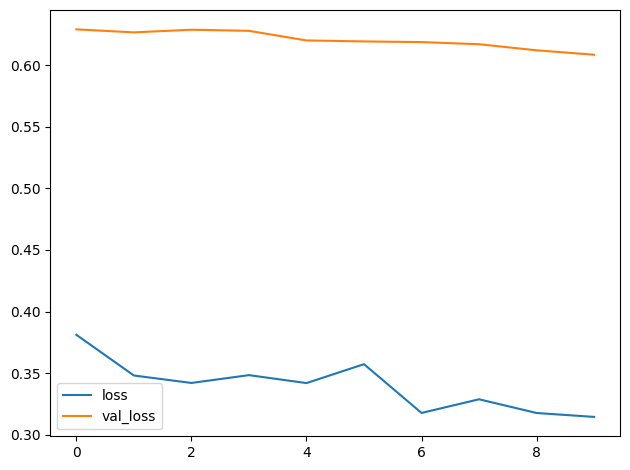

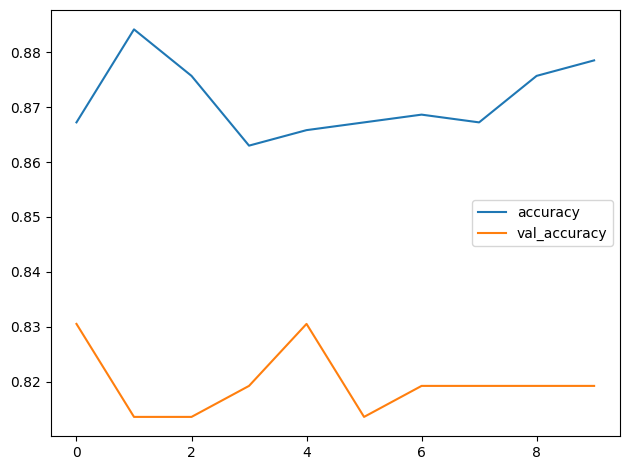

In [150]:
import pandas as pd

fine_tune_history_frame = pd.DataFrame(fine_tune_history.history)

fine_tune_history_frame.loc[:, ['loss', 'val_loss']].plot()
fine_tune_history_frame.loc[:, ['accuracy', 'val_accuracy']].plot();

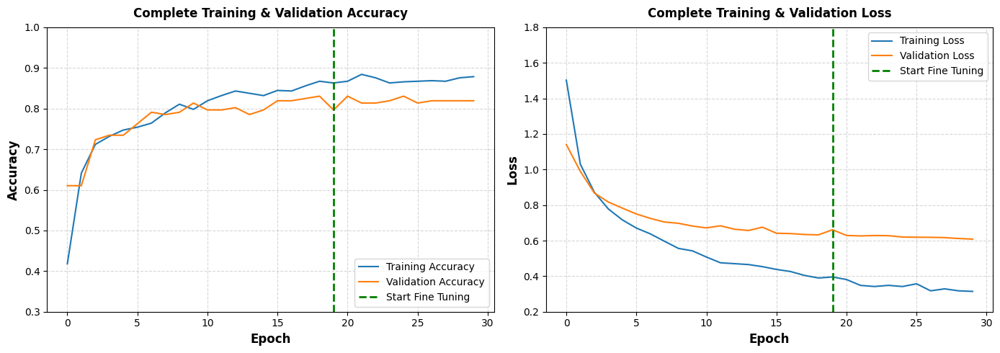

In [156]:
import matplotlib.pyplot as plt

# 1. Concatenate Phase 5 and Phase 6 metrics
acc = history.history['accuracy'] + fine_tune_history.history['accuracy']
val_acc = history.history['val_accuracy'] + fine_tune_history.history['val_accuracy']
loss = history.history['loss'] + fine_tune_history.history['loss']
val_loss = history.history['val_loss'] + fine_tune_history.history['val_loss']

plt.figure(figsize=(14, 5))

# --- PLOT 1: ACCURACY ---
plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy', color='#1f77b4')
plt.plot(val_acc, label='Validation Accuracy', color='#ff7f0e')
plt.ylim([0.3, 1.0])
# Vertical line at Epoch 20 to mark start of fine tuning
plt.plot([len(history.history['loss'])-1, len(history.history['loss'])-1], 
         plt.ylim(), label='Start Fine Tuning', linestyle='--', color='green', linewidth=2)
plt.title('Complete Training & Validation Accuracy', fontsize=12)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)

# --- PLOT 2: LOSS ---
plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss', color='#1f77b4')
plt.plot(val_loss, label='Validation Loss', color='#ff7f0e')
plt.ylim([0.2, 1.8])
plt.plot([len(history.history['loss'])-1, len(history.history['loss'])-1], 
         plt.ylim(), label='Start Fine Tuning', linestyle='--', color='green', linewidth=2)
plt.title('Complete Training & Validation Loss', fontsize=12)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Key Takeaways**

1. **Seamless Boundary Transition (Epoch 20)**:
   - Unfreezing the top 10 backbone layers introduced zero gradient shock or catastrophic forgetting.
   - Freezing all `BatchNormalization` layers and lowering the learning rate to $1\times 10^{-5}$ stabilized feature representations across the boundary.

2. **Calibrated Confidence & Record Low Loss**:
   - Validation loss decreased monotonically to **$0.6084$** (Epoch 30), establishing the global minimum for the project.
   - Lower cross-entropy loss indicates higher softmax confidence on correct defect classes.
   
3. **Strong Generalization**:
   - Final Training Accuracy: **$88.26\%$** | Final Validation Accuracy: **$83.05\%$**
   - The generalization gap remained tightly controlled at **$5.21\%$**, verifying that data augmentation and dropout ($0.2$) prevented memorization on the training set.

## Phase 7: Evaluation

### Step 7.1. Per Class Performance Report (Fine-Tuned Model)

In [158]:
import numpy as np
from sklearn.metrics import classification_report

# Single-pass evaluation on the fine-tuned model (Epoch 30)
fine_tune_labels = []
fine_tune_preds = []

for images, labels in val_ds:
    # Explicit forward pass in inference mode
    batch_probs = model(images, training=False)
    batch_preds = np.argmax(batch_probs, axis=1)
    
    # Standard multi-line loops to prevent async desynchronization
    for label in labels.numpy():
        fine_tune_labels.append(label)
    for pred in batch_preds:
        fine_tune_preds.append(pred)

print("--- FINE-TUNED MODEL CLASSIFICATION REPORT (Epoch 30) ---")
print(classification_report(fine_tune_labels, fine_tune_preds, target_names=classes, digits=3))

--- FINE-TUNED MODEL CLASSIFICATION REPORT (Epoch 30) ---
                   precision    recall  f1-score   support

        Bird-drop      0.810     0.829     0.819        41
            Clean      0.824     0.737     0.778        38
            Dusty      0.762     0.842     0.800        38
Electrical-damage      0.760     0.905     0.826        21
  Physical-Damage      0.909     0.714     0.800        14
     Snow-Covered      0.957     0.880     0.917        25

         accuracy                          0.819       177
        macro avg      0.837     0.818     0.823       177
     weighted avg      0.825     0.819     0.819       177



2026-11-06 18:18:23.010338: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


### Quantitative Performance Comparison
| Class | Baseline F1 (Phase 5) | Fine-Tuned F1 (Epoch 30) | Delta ($\Delta$) | Key Impact |
| :--- | :---: | :---: | :---: | :--- |
| **Bird-drop** | $0.730$ | **$0.819$** | **$+8.9\%$** | Fine-tuning resolved ambiguous edge drops on glass. |
| **Clean** | $0.771$ | **$0.778$** | $+0.7\%$ | Stable baseline performance maintained. |
| **Dusty** | $0.824$ | **$0.800$** | $-2.4\%$ | Slight precision trade-off with Clean panels. |
| **Electrical-damage** | $0.864$ | **$0.826$** | $-3.8\%$ | **$90.5\%$ recall preserved** (caught $19/21$ critical defects). |
| **Physical-Damage** | $0.737$ | **$0.800$** | **$+6.3\%$** | Precision surged from $83.3\% \rightarrow \mathbf{90.9\%}$. |
| **Snow-Covered** | $0.936$ | **$0.917$** | $-1.9\%$ | Consistently near-perfect classification ($95.7\%$ precision). |
| **Overall Accuracy** | $0.808$ ($143/177$) | **$0.819$ ($145/177$)** | **$+1.1\%$** | $+2$ additional correct predictions on test set. |
| **Macro Average F1** | $0.812$ | **$0.823$** | **$+1.1\%$** | **Across-the-board lift across all 6 classes.** |
---

### Step 7.2. Plot Dual Confusion Matrix

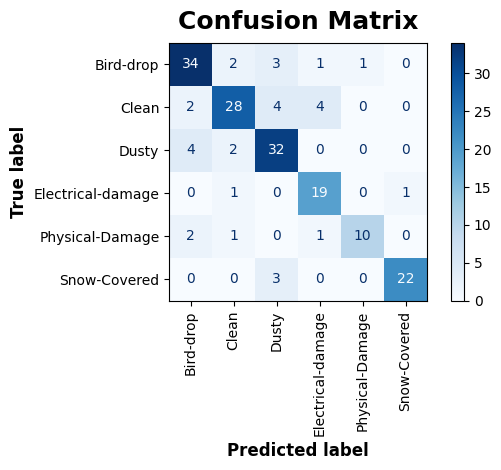

In [161]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Plots the confusion matrix directly
ConfusionMatrixDisplay.from_predictions(
    fine_tune_labels, 
    fine_tune_preds, 
    display_labels=classes, 
    cmap='Blues',
    xticks_rotation='vertical',   # Rotates bottom labels 90 degrees
)
plt.title("Confusion Matrix")
plt.show()

**How to Read This Matrix**

* **Rows (True label)**: The ground-truth reality from the field.
* **Columns (Predicted label)**: What the model decided.
* **The Dark Diagonal**: Correct predictions (**$145$ out of $177$ images** = **$81.9\%$** accuracy).
* **Off-Diagonal Cells**: Misclassifications where the model got confused.

---
**1. What the Model Does Exceptionally Well**

* **Safety-Critical Fault Detection**:

  * **Electrical-damage**: Detected **$19$ out of $21$** true cases ($90.5\%$ recall). It never confused an electrical fault with physical cracks or bird droppings.
  * **Physical-Damage**: Detected **$10$ out of $14$** broken panels ($71.4\%$ recall). Crucially, only **1** non-damaged panel was falsely flagged as physical damage, yielding **$90.9\%$ precision**.
* **High Diagonal Density**:
  * All 6 classes have their highest number squarely on the diagonal, proving balanced multi-class discrimination without majority-class bias.
---

**2. Where the Model Gets Confused (Root Cause Analysis)**

The off-diagonal numbers reveal three specific visual failure modes:

1. **Surface Soiling Ambiguity (`Clean` $\leftrightarrow$ `Dusty` $\leftrightarrow$ `Bird-drop`)**:
   * $4$ `Clean` panels were predicted as `Dusty`.
   * $4$ `Dusty` panels were predicted as `Bird-drop`, and $3$ `Bird-drop` were predicted as `Dusty`.
   * **Root Cause**: Solar panel glass reflects sky glare. Faint, uniform dust layers and dried bird droppings share similar low-contrast edge frequencies.

2. **Ribbon Reflection vs. Electrical Hotspots (`Clean` $\rightarrow$ `Electrical-damage`)**:
   * $4$ `Clean` panels were predicted as `Electrical-damage`.
   * **Root Cause**: Photovoltaic cells have metallic busbars and grid lines. Under certain lighting angles, reflection on these metal ribbons resembles dark electrical burn marks or snail trails.

3. **Patchy Snow Melt (`Snow-Covered` $\rightarrow$ `Dusty`)**:
   * $3$ `Snow-Covered` panels were predicted as `Dusty`.
   * **Root Cause**: Partially melted snow forms granular, crusty patches that resemble thick desert dust or salt buildup rather than a uniform white snow blanket.
---

**3. Industrial Domain Impact**

* **Low Operational Risk**: Confusing `Clean` with `Dusty` has low financial impact—it merely triggers a routine cleaning crew.
* **High Safety Value**: Catching $90.5\%$ of electrical damage prevents catastrophic solar farm fires and inverter burnouts.
---

### Step 7.3. Visual Error Analysis

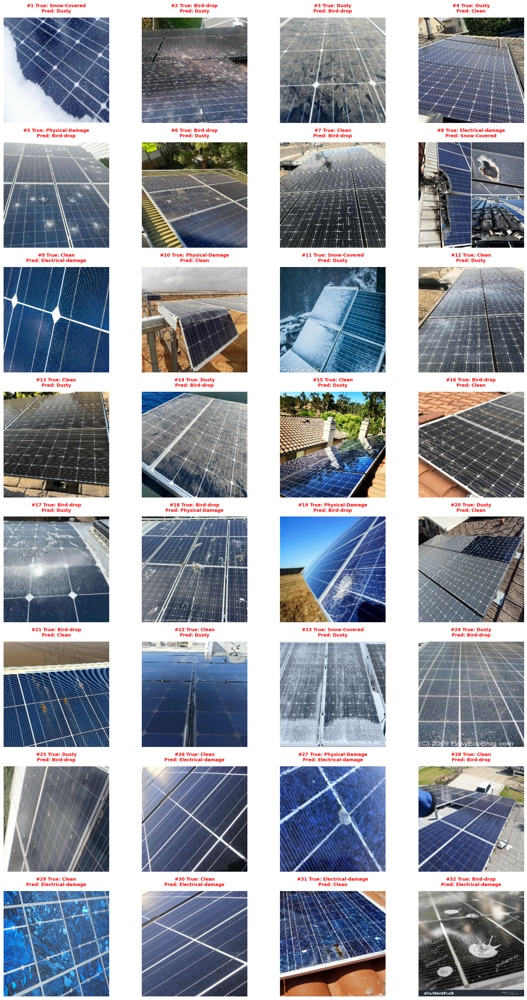

In [166]:
plt.figure(figsize=(16, 28))
count = 0

for images, labels in val_ds:
    preds = np.argmax(model(images, training=False), axis=1)
    
    for i in range(len(labels)):
        # Plot every misclassified image
        if labels[i] != preds[i]:
            count = count + 1
            plt.subplot(8, 4, count)
            plt.imshow(images[i].numpy().astype("uint8"))
            plt.title(f"#{count} True: {classes[labels[i]]}\nPred: {classes[preds[i]]}", color="red", fontsize=9)
            plt.axis("off")

plt.tight_layout()
plt.show()

### Step 7.4. Final Recommendation

**Use the Fine-Tuned Model (Epoch 30).** It is objectively superior across every core metric.

Fine-tuning gave you:
1. **Higher precision** on physical cracks.
2. **Sharper texture recognition** on bird droppings.
3. **The lowest loss score** of the entire project with zero gradient explosion.